# 客户流失探索性数据分析

## 1. 分析目标

本阶段旨在通过探索性数据分析识别与客户流失相关的主要特征，并进一步确定需要重点关注的客户群体。

主要分析问题包括：

1. 当前客户整体流失情况如何？
2. 合同类型是否与客户流失有关？
3. 客户在网时长是否与客户流失有关？
4. 月度费用较高的客户是否更容易流失？
5. 不同互联网服务类型的客户流失情况是否存在差异？
6. 是否使用技术支持服务与客户流失是否存在关系？
7. 支付方式是否与客户流失有关？
8. 网络安全等增值服务是否与客户流失有关？

In [1]:
import pandas as pd
df = pd.read_csv("../data/processed/customer_churn_cleaned.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.shape

(7043, 21)

In [3]:
df["TotalCharges"].dtype

dtype('float64')

## 2. 客户整体流失情况

首先分析客户整体流失比例，以了解当前数据集中客户流失问题的基本规模。

In [4]:
churn_rate = (df["Churn"].value_counts(normalize = True).mul(100).round(2)) 
churn_rate

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

In [5]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [6]:
import matplotlib.pyplot as plt
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False

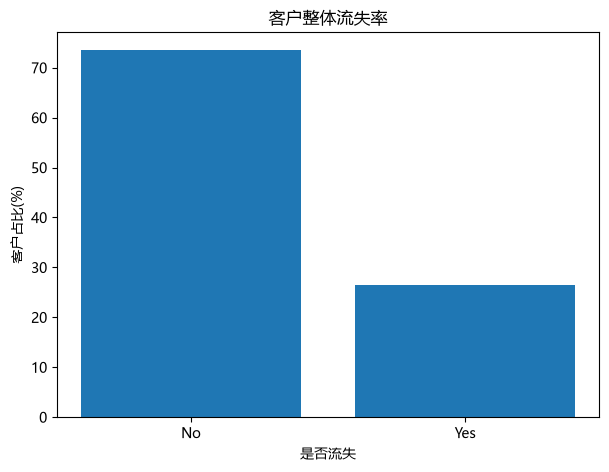

In [7]:
plt.figure(figsize = (7, 5))
plt.bar(churn_rate.index,churn_rate.values)
plt.title("客户整体流失率")
plt.xlabel("是否流失")
plt.ylabel("客户占比(%)")
plt.show()

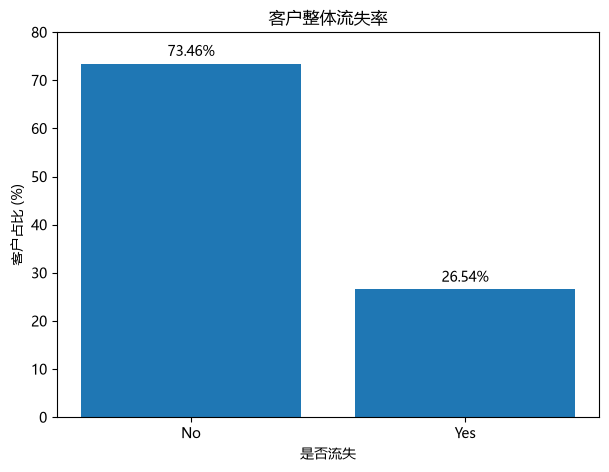

In [8]:
plt.figure(figsize=(7, 5))

bars = plt.bar(
    churn_rate.index,
    churn_rate.values
)

plt.title("客户整体流失率")
plt.xlabel("是否流失")
plt.ylabel("客户占比 (%)")

plt.bar_label(
    bars,
    fmt="%.2f%%",# .2f%%表示保留两位小数并加上百分号
    padding=3
)

plt.ylim(0, 80)

plt.show()

## 3. 合同类型与客户流失

为了判断不同合同类型的客户是否具有不同的流失风险，本节比较 Month-to-month、One year 和 Two year 三类客户的流失率。

In [9]:
pd.crosstab(df["Contract"], df["Churn"])

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


In [10]:
contract_churn = pd.crosstab(df["Contract"], df["Churn"], normalize = "index").mul(100)
contract_churn

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


In [11]:
contract_churn_rate = contract_churn["Yes"]
contract_churn_rate

Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: Yes, dtype: float64

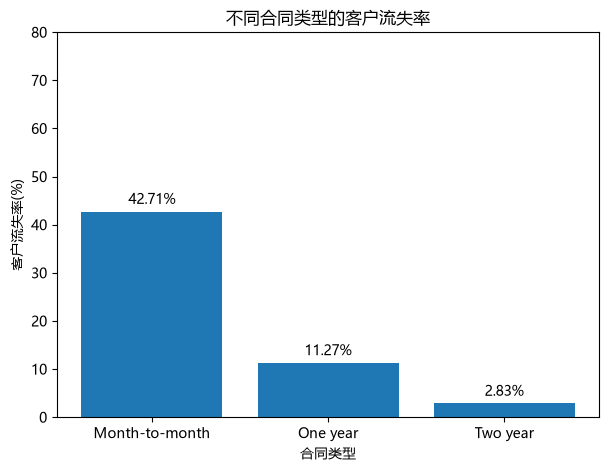

In [12]:
plt.figure(figsize = (7 , 5))
bars = plt.bar(contract_churn_rate.index, contract_churn_rate.values)
plt.title("不同合同类型的客户流失率")
plt.xlabel("合同类型")
plt.ylabel("客户流失率(%)")

plt.bar_label(bars, fmt="%.2f%%", padding=3)
plt.ylim(0, 80)
plt.show()

### 分析结果

不同合同类型客户的流失率存在明显差异。

- Month-to-month 客户流失率最高，为 42.71%
- One year 客户流失率为 11.27%
- Two year 客户流失率最低，仅为 2.83%

这表明短期合同客户与较高的流失风险存在明显关联，因此 Month-to-month 客户可以作为后续客户留存分析中的重点关注群体。

但该结果只能说明合同类型与客户流失之间存在相关关系，不能直接证明短期合同导致客户流失。客户在网时长、月度费用和服务类型等其他因素也可能同时影响客户流失。

## 4. 在网时长与客户流失

本节分析客户在网时长（tenure）与客户流失之间的关系，以判断新客户和长期客户是否具有不同的流失风险。

In [13]:
df.groupby("Churn")["tenure"].mean()

Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64

In [14]:
df.groupby("Churn")["tenure"].median()

Churn
No     38.0
Yes    10.0
Name: tenure, dtype: float64

### 在网时长分布

从平均值和中位数来看，流失客户的在网时长明显低于未流失客户。为了进一步观察两组客户在网时长的整体分布，使用箱线图进行比较。

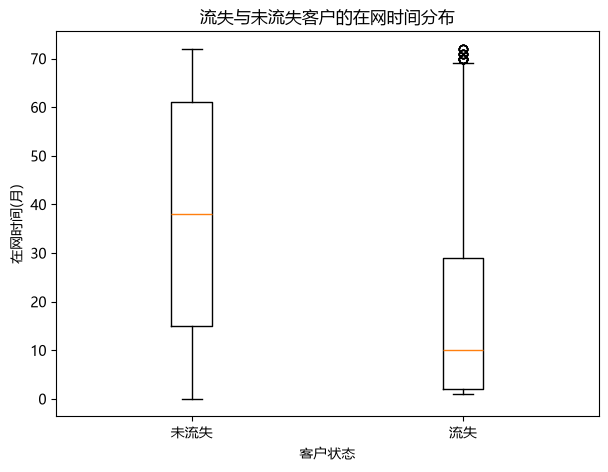

In [15]:
plt.figure(figsize = (7, 5))
plt.boxplot([df.loc[df["Churn"]=="No","tenure"], df.loc[df["Churn"]=="Yes","tenure"]], tick_labels=["未流失", "流失"])
plt.title("流失与未流失客户的在网时间分布")
plt.xlabel("客户状态")
plt.ylabel("在网时间(月)")
plt.show()

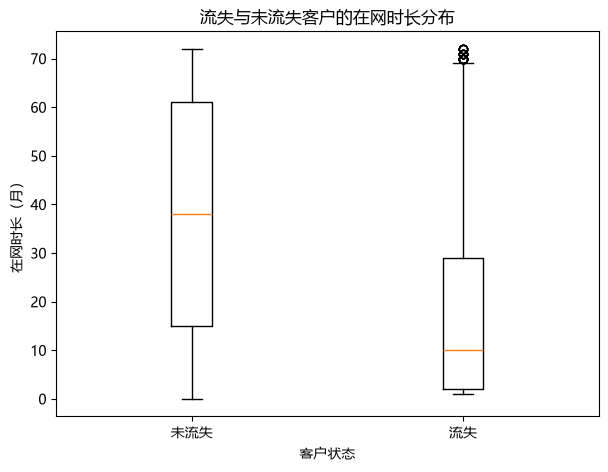

In [16]:
no_churn_tenure = df.loc[df["Churn"]=="No", "tenure"]
yes_churn_tenure = df.loc[df["Churn"]=="Yes", "tenure"]
plt.figure(figsize = (7, 5))
plt.boxplot([no_churn_tenure, yes_churn_tenure], tick_labels=["未流失", "流失"])
plt.title("流失与未流失客户的在网时长分布")
plt.xlabel("客户状态")
plt.ylabel("在网时长（月）")

plt.show()

### 客户生命周期阶段与流失

为了进一步分析在网时长与客户流失之间的关系，将客户按照在网时长划分为不同生命周期阶段，并比较各阶段的客户流失率。

In [17]:
df["tenure_group"] = pd.cut(df["tenure"], bins = [0, 12, 24, 48, 72], labels = ["0-12个月", "13-24个月", "25-48个月", "49-72个月"], include_lowest = True)

In [18]:
df[["tenure","tenure_group"]].head(10)

,tenure,tenure_group
0,1,0-12个月
1,34,25-48个月
2,2,0-12个月
3,45,25-48个月
4,2,0-12个月
5,8,0-12个月
6,22,13-24个月
7,10,0-12个月
8,28,25-48个月
9,62,49-72个月


In [19]:
df["tenure_group"].value_counts().sort_index()

tenure_group
0-12个月     2186
13-24个月    1024
25-48个月    1594
49-72个月    2239
Name: count, dtype: int64

In [20]:
tenure_churn = pd.crosstab(df["tenure_group"],df["Churn"], normalize = "index").mul(100)
tenure_churn

Churn,No,Yes
tenure_group,,
0-12个月,52.561757,47.438243
13-24个月,71.289062,28.710938
25-48个月,79.611041,20.388959
49-72个月,90.486824,9.513176


In [21]:
tenure_churn_rate = tenure_churn["Yes"]
tenure_churn_rate

tenure_group
0-12个月     47.438243
13-24个月    28.710938
25-48个月    20.388959
49-72个月     9.513176
Name: Yes, dtype: float64

In [22]:
tenure_churn_rate = tenure_churn["Yes"].round(2)
tenure_churn_rate

tenure_group
0-12个月     47.44
13-24个月    28.71
25-48个月    20.39
49-72个月     9.51
Name: Yes, dtype: float64

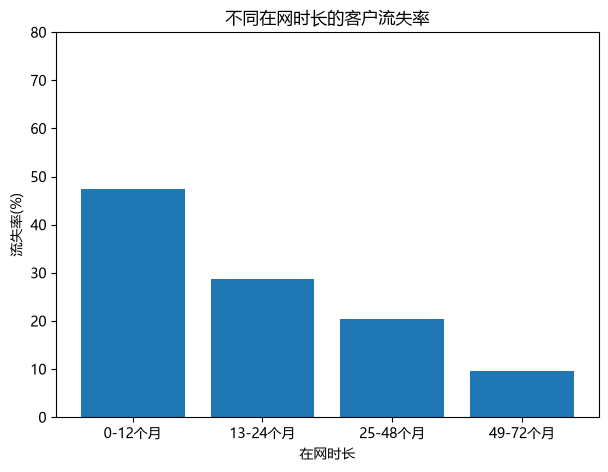

In [23]:
plt.figure(figsize = (7, 5))
bars = plt.bar(tenure_churn_rate.index, tenure_churn_rate.values)
plt.title("不同在网时长的客户流失率")
plt.xlabel("在网时长")
plt.ylabel("流失率(%)")
plt.ylim(0, 80)
plt.show()

## 5. 月度费用与客户流失

本节通过比较流失客户与未流失客户的月度费用，分析月度费用是否与客户流失存在关联。

In [24]:
df.groupby("Churn")["MonthlyCharges"].mean()

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64

In [25]:
df.groupby("Churn")["MonthlyCharges"].median()

Churn
No     64.425
Yes    79.650
Name: MonthlyCharges, dtype: float64

In [26]:
charge_summary = (df.groupby("Churn")["MonthlyCharges"].agg(["count","mean", "median"]).round(2))
charge_summary

,count,mean,median
Churn,,,
No,5174,61.27,64.43
Yes,1869,74.44,79.65


### 月度费用分析结果

流失客户的平均月费为 74.44，高于未流失客户的 61.27。两组客户的月费中位数分别为 79.65 和 64.43。

这一结果说明流失客户整体上具有更高的月度费用水平，但不能据此认定较高的月费直接导致客户流失。

不同客户可能使用不同的互联网服务、合同类型或增值服务，这些因素可能同时与月费和流失情况有关。

因此，后续需要进一步结合服务类型等变量开展分组分析。

In [27]:
df.groupby("InternetService")["MonthlyCharges"].mean()

InternetService
DSL            58.102169
Fiber optic    91.500129
No             21.079194
Name: MonthlyCharges, dtype: float64

In [28]:
service_charges = (df.groupby("InternetService")["MonthlyCharges"].agg(["count", "mean", "median"]).round(2))
service_charges

,count,mean,median
InternetService,,,
DSL,2421,58.10,56.15
Fiber optic,3096,91.50,91.68
No,1526,21.08,20.15


### 不同互联网服务类型与客户流失

为进一步研究月度费用与客户流失之间的关系，首先比较不同互联网服务类型的客户流失率，以判断服务类型是否可能与客户流失存在关联。

In [29]:
service_churn = pd.crosstab(df["InternetService"], df["Churn"], normalize = "index").mul(100).round(2)
service_churn

Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


In [30]:
service_churn_rate = service_churn["Yes"].round(2)
service_churn_rate

InternetService
DSL            18.96
Fiber optic    41.89
No              7.40
Name: Yes, dtype: float64

### 网络服务类型与客户流失分析结果

光纤客户的平均月费为 91.50，高于 DSL 客户的 58.10。

同时，光纤客户的流失率为 41.89%，明显高于 DSL 客户的 18.96%。

这一结果表明，互联网服务类型、月度费用和客户流失之间可能存在关联。

但是，现有分析无法确认较高月费是否直接导致客户流失。后续将进一步结合月费区间和客户在网时长进行分层分析。

In [31]:
df["charge_group"] = pd.qcut(df["MonthlyCharges"], q = 3, labels=["低月费", "中月费", "高月费"])

In [32]:
df.groupby("charge_group", observed = True)["MonthlyCharges"].agg(["count", "min", "max"]).round(2)

,count,min,max
charge_group,,,
低月费,2351,18.25,50.40
中月费,2345,50.45,83.90
高月费,2347,83.95,118.75


In [33]:
charge_churn = pd.crosstab(df["charge_group"],df["Churn"],normalize="index").mul(100).round(2)
charge_churn

Churn,No,Yes
charge_group,,
低月费,84.13,15.87
中月费,70.32,29.68
高月费,65.91,34.09


In [34]:
charge_churn_rate = charge_churn["Yes"].round(2)
charge_churn_rate

charge_group
低月费    15.87
中月费    29.68
高月费    34.09
Name: Yes, dtype: float64

In [35]:
df["is_churn"] = df["Churn"].eq("Yes")

In [36]:
segment_analysis = df.groupby(["tenure_group","charge_group"], observed = True).agg(customers = ("is_churn", "size"), churn_rate = ("is_churn", "mean"))
segment_analysis["churn_rate"] = (segment_analysis["churn_rate"] * 100).round(2)
segment_analysis

customers  churn_rate
tenure_group charge_group                       
0-12个月       低月费                 949       30.98
             中月费                 860       54.07
             高月费                 377       73.74
13-24个月      低月费                 361       10.53
             中月费                 369       28.46
             高月费                 294       51.36
25-48个月      低月费                 492        5.49
             中月费                 521       17.85
             高月费                 581       35.28
49-72个月      低月费                 549        2.55
             中月费                 595        5.55
             高月费                1095       15.16

In [37]:
churn_matrix = segment_analysis["churn_rate"].unstack("charge_group")
churn_matrix

charge_group,低月费,中月费,高月费
tenure_group,,,
0-12个月,30.98,54.07,73.74
13-24个月,10.53,28.46,51.36
25-48个月,5.49,17.85,35.28
49-72个月,2.55,5.55,15.16


In [38]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


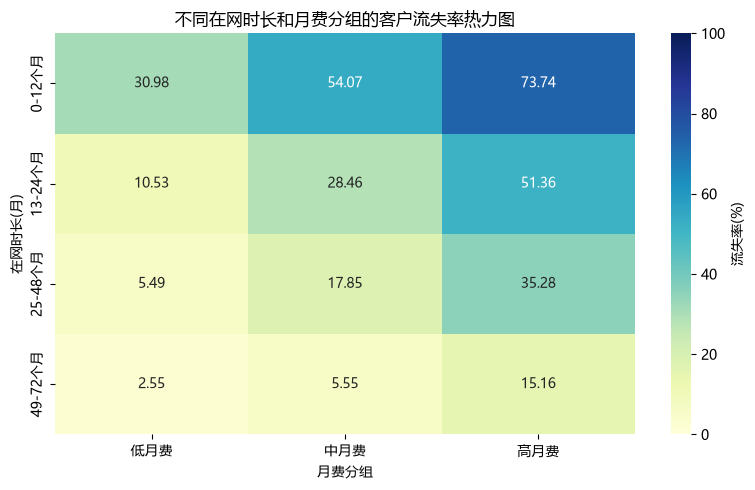

In [39]:
import seaborn as sns
plt.figure(figsize = (8, 5))
sns.heatmap(churn_matrix, annot = True, fmt = ".2f", cmap = "YlGnBu", vmin = 0, vmax = 100, cbar_kws = {"label": "流失率(%)"})
plt.title("不同在网时长和月费分组的客户流失率热力图")
plt.xlabel("月费分组")
plt.ylabel("在网时长(月)")
plt.tight_layout()
plt.show()

In [40]:
customer_matrix = segment_analysis["customers"].unstack("charge_group")
customer_matrix

charge_group,低月费,中月费,高月费
tenure_group,,,
0-12个月,949,860,377
13-24个月,361,369,294
25-48个月,492,521,581
49-72个月,549,595,1095


In [41]:
segment_priority = (df.groupby(["tenure_group", "charge_group"], observed = True)).agg(customers = ("is_churn", "size"), churned_customers = ("is_churn", "sum"), churn_rate = ("is_churn", "mean"))
segment_priority["churn_rate"] = (segment_priority["churn_rate"] * 100).round(2)
segment_priority

customers  churned_customers  churn_rate
tenure_group charge_group                                          
0-12个月       低月费                 949                294       30.98
             中月费                 860                465       54.07
             高月费                 377                278       73.74
13-24个月      低月费                 361                 38       10.53
             中月费                 369                105       28.46
             高月费                 294                151       51.36
25-48个月      低月费                 492                 27        5.49
             中月费                 521                 93       17.85
             高月费                 581                205       35.28
49-72个月      低月费                 549                 14        2.55
             中月费                 595                 33        5.55
             高月费                1095                166       15.16

In [42]:
top5_segments = segment_priority.sort_values("churned_customers",ascending=False).head(5)
top5_segments

customers  churned_customers  churn_rate
tenure_group charge_group                                          
0-12个月       中月费                 860                465       54.07
             低月费                 949                294       30.98
             高月费                 377                278       73.74
25-48个月      高月费                 581                205       35.28
49-72个月      高月费                1095                166       15.16

In [43]:
new_customer_segments = segment_priority.loc["0-12个月"]
new_customer_segments

,customers,churned_customers,churn_rate
charge_group,,,
低月费,949,294,30.98
中月费,860,465,54.07
高月费,377,278,73.74


In [44]:
new_customer_segments.sort_values("churned_customers", ascending = False).head(5)
new_customer_segments

,customers,churned_customers,churn_rate
charge_group,,,
低月费,949,294,30.98
中月费,860,465,54.07
高月费,377,278,73.74


## 6. 客户价值与留存决策（模拟分析）

本节通过假设客户案例理解流失风险、客户价值、留存干预效果及成本之间的关系。

以下参数仅用于演示决策逻辑，并非 IBM 数据集中的实际利润、预测结果或干预效果。

In [51]:
import pandas as pd
demo_customers = pd.DataFrame({"customer_id":["A", "B"],"churn_prob":[0.80, 0.50],"monthly_profit":[20, 200], "rescue_rate":[0.25, 0.25], "contact_cost":[10, 10]})
demo_customers

,customer_id,churn_prob,monthly_profit,rescue_rate,contact_cost
0,A,0.8,20,0.25,10
1,B,0.5,200,0.25,10


In [52]:
months_saved = 6
demo_customers["value_if_saved"] = (demo_customers["monthly_profit"] * months_saved )
demo_customers

,customer_id,churn_prob,monthly_profit,rescue_rate,contact_cost,value_if_saved
0,A,0.8,20,0.25,10,120
1,B,0.5,200,0.25,10,1200


In [53]:
demo_customers["expected_net_benefit"] = (demo_customers["churn_prob"] * demo_customers["rescue_rate"] * demo_customers["value_if_saved"]) - demo_customers["contact_cost"].round(2)
demo_customers 

,customer_id,churn_prob,monthly_profit,rescue_rate,contact_cost,value_if_saved,expected_net_benefit
0,A,0.8,20,0.25,10,120,14.0
1,B,0.5,200,0.25,10,1200,140.0


In [54]:
demo_customers.sort_values("expected_net_benefit",ascending=False)

,customer_id,churn_prob,monthly_profit,rescue_rate,contact_cost,value_if_saved,expected_net_benefit
1,B,0.5,200,0.25,10,1200,140.0
0,A,0.8,20,0.25,10,120,14.0


In [55]:
demo_customers.loc[demo_customers["customer_id"] == "B", "rescue_rate"] = 0.01

In [56]:
# 重新计算预期净收益
demo_customers["expected_net_benefit"] = (
    demo_customers["churn_prob"]
    * demo_customers["rescue_rate"]
    * demo_customers["value_if_saved"]
    - demo_customers["contact_cost"]
).round(2)

# 按预期收益从大到小排序
demo_customers[
    ["customer_id", "rescue_rate", "expected_net_benefit"]
].sort_values(
    "expected_net_benefit",
    ascending=False
)

,customer_id,rescue_rate,expected_net_benefit
0,A,0.25,14.0
1,B,0.01,-4.0
